In [1]:
import pandas as pd
import numpy as np
import xgi
import networkx as nx
from preprocessing import create_hypergraph
import matplotlib.pyplot as plt
import powerlaw
from collections import Counter
import ast
from utils import *

In [ ]:
proteins = pd.read_csv('data/final_proteins.csv')
condensates = pd.read_csv('data/final_condensates.csv')
mapping = pd.read_csv('CD-Code Dump 17_12_25/01/protein2cdcode_v2.1.tsv', sep='\t', header=0)
H = create_hypergraph(proteins, condensates, mapping, min_proteins=3)

In [ ]:
df = pd.read_csv('data/df_with_roles.csv')
df.head()

,uniprotkb_ac,condensate_id,condensate_name,uid,confidence_score,condensate_type,protein_count,uniprot_id,uniprotkb_id,protein_name,species_taxon_id,species_name,iupred_score,synthetic_condensate_count,role
0,Q92804,462A97B5,Leucocyte nuclear body,462A97B5,0.0,biomolecular,21.0,Q92804,RBP56_HUMAN,TATA-binding protein-associated factor 2N,9606.0,Homo sapiens,"[0.754692, 0.76285, 0.808535, 0.827927, 0.8375...",5.0,member
1,O43791,462A97B5,Leucocyte nuclear body,462A97B5,0.0,biomolecular,21.0,O43791,SPOP_HUMAN,Speckle-type POZ protein,9606.0,Homo sapiens,"[0.690604, 0.724957, 0.657645, 0.653063, 0.653...",3.0,member
2,Q16082,462A97B5,Leucocyte nuclear body,462A97B5,0.0,biomolecular,21.0,Q16082,HSPB2_HUMAN,Heat shock protein beta-2,9606.0,Homo sapiens,"[0.775545, 0.733139, 0.767246, 0.728858, 0.762...",0.0,driver
3,Q92804,38EC0B30,Transcriptional condensate,38EC0B30,1.0,biomolecular,41.0,Q92804,RBP56_HUMAN,TATA-binding protein-associated factor 2N,9606.0,Homo sapiens,"[0.754692, 0.76285, 0.808535, 0.827927, 0.8375...",5.0,NaN
4,P14866,62EA6512,Sam68 nuclear body,62EA6512,1.0,biomolecular,15.0,P14866,HNRPL_HUMAN,Heterogeneous nuclear ribonucleoprotein L,9606.0,Homo sapiens,"[0.823549, 0.84206, 0.856457, 0.868118, 0.8765...",0.0,member


In [4]:
df.columns

Index(['uniprotkb_ac', 'condensate_id', 'condensate_name', 'uid',
       'confidence_score', 'condensate_type', 'protein_count', 'uniprot_id',
       'uniprotkb_id', 'protein_name', 'species_taxon_id', 'species_name',
       'iupred_score', 'synthetic_condensate_count', 'role'],
      dtype='str')

In [5]:
top_5_proteins = (
    df.groupby(['uniprotkb_ac', 'protein_name'])['condensate_id']
    .nunique()
    .reset_index(name='condensate_count')
    .sort_values(by='condensate_count', ascending=False)
    .head(5)
)

print(top_5_proteins)

     uniprotkb_ac                                       protein_name  \
1312       P35637                            RNA-binding protein FUS   
893        P09651  Heterogeneous nuclear ribonucleoprotein A1 OS=...   
2005       Q13148                         TAR DNA-binding protein 43   
1858       Q01844                            RNA-binding protein EWS   
3092       Q92804          TATA-binding protein-associated factor 2N   

      condensate_count  
1312                24  
893                 14  
2005                13  
1858                12  
3092                 9  


In [6]:
# Drop duplicates to count each unique condensate once per protein
bio_df = df[df['condensate_type'] == 'biomolecular']
unique_pairs = bio_df[['uniprotkb_ac', 'protein_name', 'condensate_id', 'condensate_type']].drop_duplicates()

# Count condensates by type per protein
type_counts = pd.crosstab(
    index=[unique_pairs['uniprotkb_ac'], unique_pairs['protein_name']], 
    columns=unique_pairs['condensate_type']
)

# Add total condensate count and rank the top 5
top_5_proteins = (
    type_counts
    .assign(total_condensates=lambda x: x.sum(axis=1))
    .sort_values(by='total_condensates', ascending=False)
    .head(5)
    .reset_index()
)

print(top_5_proteins)

condensate_type uniprotkb_ac  \
0                     P35637   
1                     Q01844   
2                     P09651   
3                     Q13148   
4                     Q15233   

condensate_type                                       protein_name  \
0                                          RNA-binding protein FUS   
1                                          RNA-binding protein EWS   
2                Heterogeneous nuclear ribonucleoprotein A1 OS=...   
3                                       TAR DNA-binding protein 43   
4                Non-POU domain-containing octamer-binding protein   

condensate_type  biomolecular  total_condensates  
0                          12                 12  
1                          10                 10  
2                          10                 10  
3                          10                 10  
4                           9                  9  


In [7]:
df['condensate_id'].nunique()

109

In [ ]:
unique_condensates = df.drop_duplicates(subset=['condensate_id'])

type_counts = unique_condensates['condensate_type'].value_counts()

print(type_counts)

condensate_type
biomolecular    68
synthetic       32
infectious       9
Name: count, dtype: int64


In [9]:
df[df['uniprotkb_ac'] == 'P14866']['iupred_score']

4       [0.823549, 0.84206, 0.856457, 0.868118, 0.8765...
211     [0.823549, 0.84206, 0.856457, 0.868118, 0.8765...
3511    [0.823549, 0.84206, 0.856457, 0.868118, 0.8765...
5829    [0.823549, 0.84206, 0.856457, 0.868118, 0.8765...
6124    [0.823549, 0.84206, 0.856457, 0.868118, 0.8765...
Name: iupred_score, dtype: str

In [ ]:
len(ast.literal_eval(df.loc[0, ['iupred_score']].values[0]))

592

In [11]:
sub = df.dropna(subset=['role'])
sub[sub['role'] != 'unknown'].shape

(647, 15)

In [12]:
sub['role'].unique()

<StringArray>
['member', 'driver', 'unknown']
Length: 3, dtype: str

In [17]:
df[df['uniprot_id'] == 'Q92804']['uniprotkb_ac'].unique()

<StringArray>
['Q92804']
Length: 1, dtype: str

In [18]:
np.any(df['protein_count'] < 3)

np.False_

In [19]:
print(f"DataFrame shape: {df.shape}")
print(f"Number of unique condensates: {len(set(df['condensate_id']))}")
print(f"Number of unique proteins: {len(set(df['uniprot_id']))}")

DataFrame shape: (6885, 15)
Number of unique condensates: 109
Number of unique proteins: 4352


In [20]:
df['condensate_type'].unique()

<StringArray>
['biomolecular', 'synthetic', 'infectious']
Length: 3, dtype: str

In [ ]:
describe_hypergraph(H)

In [23]:
print(f"Hypergraph assortativity coefficient: {xgi.degree_assortativity(H)}")

Hypergraph assortativity coefficient: 0.296115273042534


In [24]:
print(xgi.connected_components(H))

<generator object connected_components at 0x000002349EF9CA90>


In [25]:
print(f"Number of Connected Components: {xgi.number_connected_components(H)}")
print(f"\nConnected Components Sizes: {[len(component) for component in xgi.connected_components(H)]}")
print(f"\nSmallest Connected Component Elements: {[component for component in xgi.connected_components(H)][1]}")

Number of Connected Components: 2

Connected Components Sizes: [4349, 3]

Smallest Connected Component Elements: {'Q9C035', 'Q13049', 'Q969Q1'}


In [26]:
sep_components = [component for component in xgi.connected_components(H)][1]

names = df[df['uniprot_id'].isin(list(sep_components))]

names

,uniprotkb_ac,condensate_id,condensate_name,uid,confidence_score,condensate_type,protein_count,uniprot_id,uniprotkb_id,protein_name,species_taxon_id,species_name,iupred_score,synthetic_condensate_count,role
4748,Q13049,1C4BF022,Cytoplasmic bodies,1C4BF022,4.0,biomolecular,3.0,Q13049,TRI32_HUMAN,E3 ubiquitin-protein ligase TRIM32,9606.0,Homo sapiens,"[0.073402, 0.109221, 0.106997, 0.066181, 0.090...",0.0,member
4761,Q9C035,1C4BF022,Cytoplasmic bodies,1C4BF022,4.0,biomolecular,3.0,Q9C035,TRIM5_HUMAN,Tripartite motif-containing protein 5,9606.0,Homo sapiens,"[0.196879, 0.257454, 0.203355, 0.243554, 0.090...",0.0,member
4763,Q969Q1,1C4BF022,Cytoplasmic bodies,1C4BF022,4.0,biomolecular,3.0,Q969Q1,TRI63_HUMAN,E3 ubiquitin-protein ligase TRIM63,9606.0,Homo sapiens,"[0.222385, 0.275179, 0.342579, 0.321458, 0.366...",0.0,member


In [27]:
df[df['condensate_name']=="Cytoplasmic bodies"]

,uniprotkb_ac,condensate_id,condensate_name,uid,confidence_score,condensate_type,protein_count,uniprot_id,uniprotkb_id,protein_name,species_taxon_id,species_name,iupred_score,synthetic_condensate_count,role
4748,Q13049,1C4BF022,Cytoplasmic bodies,1C4BF022,4.0,biomolecular,3.0,Q13049,TRI32_HUMAN,E3 ubiquitin-protein ligase TRIM32,9606.0,Homo sapiens,"[0.073402, 0.109221, 0.106997, 0.066181, 0.090...",0.0,member
4761,Q9C035,1C4BF022,Cytoplasmic bodies,1C4BF022,4.0,biomolecular,3.0,Q9C035,TRIM5_HUMAN,Tripartite motif-containing protein 5,9606.0,Homo sapiens,"[0.196879, 0.257454, 0.203355, 0.243554, 0.090...",0.0,member
4763,Q969Q1,1C4BF022,Cytoplasmic bodies,1C4BF022,4.0,biomolecular,3.0,Q969Q1,TRI63_HUMAN,E3 ubiquitin-protein ligase TRIM63,9606.0,Homo sapiens,"[0.222385, 0.275179, 0.342579, 0.321458, 0.366...",0.0,member


In [28]:
df_ids = set(df["condensate_id"].unique())

H_ids = set(H.edges)

lost_ids = df_ids - H_ids
print(f"Lost IDs: {lost_ids}")
df = df[~df['condensate_id'].isin(lost_ids)]

Lost IDs: {'7ADEF05E', '54D84D15', '48B2925C', '21EC1620', '38D1B6BE', '80CC731F'}


In [29]:
# Biomolecular
bio = df[df['condensate_type'] == 'biomolecular']
print(f"Number of biomolecular condensates: {len(set(bio['condensate_id']))}")

# Synthetic
synth = df[df['condensate_type'] == 'synthetic']
print(f"Number of synthetic condensates: {len(set(synth['condensate_id']))}")
# Infectious
infec = df[df['condensate_type'] == 'infectious']
print(f"Number of infectious condensates: {len(set(infec['condensate_id']))}")
total = len(set(bio['condensate_id'])) + len(set(synth['condensate_id'])) + len(set(infec['condensate_id']))
print(f"\nQuick check\nDo condensates sum up: {total == len(set(df['condensate_id']))}")

Number of biomolecular condensates: 68
Number of synthetic condensates: 31
Number of infectious condensates: 4

Quick check
Do condensates sum up: True


In [30]:
# Extract unique protein counts per condensate ID
bio_counts = bio.groupby('condensate_id')['protein_count'].first()
synth_counts = synth.groupby('condensate_id')['protein_count'].first()
infec_counts = infec.groupby('condensate_id')['protein_count'].first()

bio_counts.describe()

count      68.00000
mean       99.25000
std       298.43124
min         3.00000
25%         3.00000
50%         5.50000
75%        15.25000
max      1413.00000
Name: protein_count, dtype: float64

In [31]:
synth_counts.describe()

count    31.000000
mean      3.935484
std       1.691853
min       3.000000
25%       3.000000
50%       3.000000
75%       4.000000
max      10.000000
Name: protein_count, dtype: float64

In [32]:
infec_counts.describe()

count    4.000000
mean     5.250000
std      1.258306
min      4.000000
25%      4.750000
50%      5.000000
75%      5.500000
max      7.000000
Name: protein_count, dtype: float64

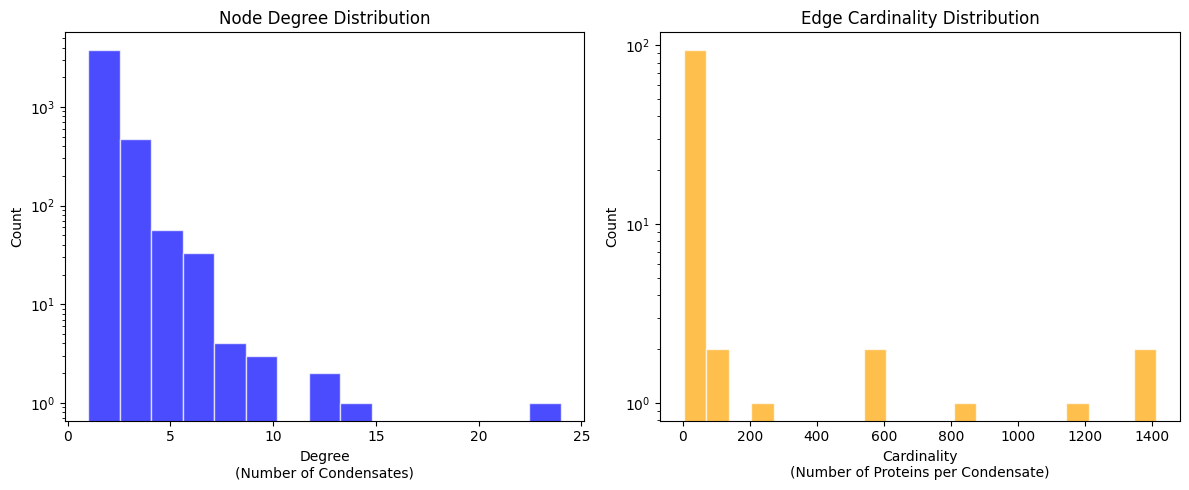

In [33]:
edge_sizes = H.edges.size.asnumpy()
edge_size_dist = Counter(edge_sizes)

degrees = H.nodes.degree.asnumpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.hist(degrees, bins=15, color='blue', edgecolor='white', alpha=0.7)
ax1.set_title("Node Degree Distribution")
ax1.set_xlabel("Degree\n(Number of Condensates)")
ax1.set_ylabel("Count")
ax1.set_yscale("log")

ax2.hist(edge_sizes, bins='auto', color='orange', edgecolor='white', alpha=0.7)

ax2.set_title("Edge Cardinality Distribution")
ax2.set_xlabel("Cardinality\n(Number of Proteins per Condensate)")
ax2.set_ylabel("Count")
ax2.set_yscale("log")

plt.tight_layout()
plt.show()

## Degree Distribution

In [34]:
fit_deg = powerlaw.Fit(degrees, discrete=True)

print(f"(Degree Distribution) Power Law Exponent (gamma): {fit_deg.power_law.alpha:.2f}")
print(f"(Degree Distribution) Minimum value for fit (xmin): {fit_deg.power_law.xmin}")

print(f"(Degree Distribution) Fraction of observations above xmin: {(100 * sum(degrees > fit_deg.power_law.xmin) / len(degrees)):.2f}%")

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 11/11 [00:00<00:00, 130.01it/s]

(Degree Distribution) Power Law Exponent (gamma): 2.43
(Degree Distribution) Minimum value for fit (xmin): 1.0
(Degree Distribution) Fraction of observations above xmin: 34.26%



c:\Users\gabri\anaconda3\envs\hypergraphs\Lib\site-packages\powerlaw\distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,


Negative Loglikelihood Ratio indicates evidence in favor of the second distribution<sup><a href="#footnote1">[1]</a></sup>

<a href="footnote1"></a>
[1] Alstott, J., Bullmore, E., & Plenz, D. (2014c). powerlaw: A Python Package for Analysis of Heavy-Tailed Distributions. PLoS ONE, 9(1), e85777. https://doi.org/10.1371/journal.pone.0085777

In [35]:
log_lik_ratio_deg, p_deg = fit_deg.distribution_compare("power_law", "exponential", normalized_ratio=True)
print(f"Loglikelihood Ratio: {log_lik_ratio_deg:2f}, p-value: {p_deg}")

Loglikelihood Ratio: -6.724807, p-value: 1.758253936645318e-11


In [36]:
log_lik_ratio_deg_logn, p_deg_logn = fit_deg.distribution_compare("power_law", "lognormal", normalized_ratio=True)
print(f"Loglikelihood Ratio: {log_lik_ratio_deg_logn:2f}, p-value: {p_deg_logn}")

Loglikelihood Ratio: -11.970730, p-value: 5.058134792258661e-33


In [37]:
log_lik_ratio_deg_explogn, p_deg_explogn = fit_deg.distribution_compare("lognormal", "exponential", normalized_ratio=True)
print(f"Loglikelihood Ratio: {log_lik_ratio_deg_explogn:2f}, p-value: {p_deg_explogn}")

Loglikelihood Ratio: 1.762855, p-value: 0.07792497638825306


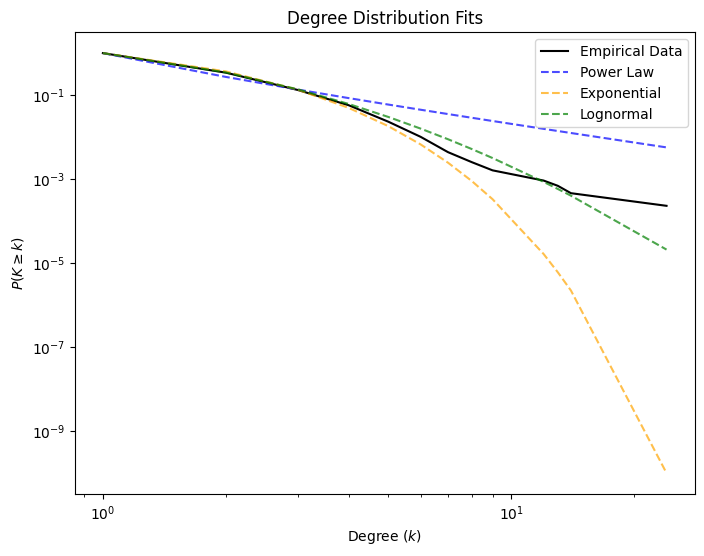

In [38]:
# Create the figure
plt.figure(figsize=(8, 6))

# Plot the empirical data (CCDF)
fit_deg.plot_ccdf(color='black', label='Empirical Data')

# Plot the fitted distributions
fit_deg.power_law.plot_ccdf(color='blue', linestyle='--', label='Power Law', alpha=0.7)
fit_deg.exponential.plot_ccdf(color='orange', linestyle='--', label='Exponential', alpha=0.7)
fit_deg.lognormal.plot_ccdf(color='green', linestyle='--', label='Lognormal', alpha=0.7)

# Formatting the plot
plt.xlabel('Degree ($k$)')
plt.ylabel('$P(K \\geq k)$')
plt.title('Degree Distribution Fits')
plt.legend()
plt.show()

## Edge Cardinalities

In [39]:
fit_card = powerlaw.Fit(edge_sizes, discrete=True)

print(f"(Edge Cardinalities) Power Law Exponent (gamma): {fit_card.power_law.alpha:.2f}")
print(f"(Edge Cardinalities) Minimum value for fit (xmin): {fit_card.power_law.xmin}")

print(f"(Edge Cardinalities) Fraction of observations above xmin: {(100 * sum(degrees > fit_deg.power_law.xmin) / len(degrees)):.2f}%")

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 27/27 [00:00<00:00, 347.59it/s]

(Edge Cardinalities) Power Law Exponent (gamma): 1.56
(Edge Cardinalities) Minimum value for fit (xmin): 8.0
(Edge Cardinalities) Fraction of observations above xmin: 34.26%


In [40]:
log_lik_ratio_card, p_card = fit_card.distribution_compare("power_law", "exponential", normalized_ratio=True)
print(f"Loglikelihood Ratio: {log_lik_ratio_card:2f}, p-value: {p_card}")

Loglikelihood Ratio: 4.065060, p-value: 4.8020012531214555e-05


c:\Users\gabri\anaconda3\envs\hypergraphs\Lib\site-packages\powerlaw\distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution exponential; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')


In [41]:
log_lik_ratio_card_logn, p_card_logn = fit_card.distribution_compare("power_law", "lognormal", normalized_ratio=True)
print(f"Loglikelihood Ratio: {log_lik_ratio_card_logn:2f}, p-value: {p_card_logn}")

Loglikelihood Ratio: -0.209577, p-value: 0.8339975527145675


In [42]:
log_lik_ratio_card_exp, p_card_exp = fit_card.distribution_compare("lognormal", "exponential", normalized_ratio=True)
print(f"Loglikelihood Ratio: {log_lik_ratio_card_exp:2f}, p-value: {p_card_exp}")

Loglikelihood Ratio: 4.082614, p-value: 4.453187553448798e-05


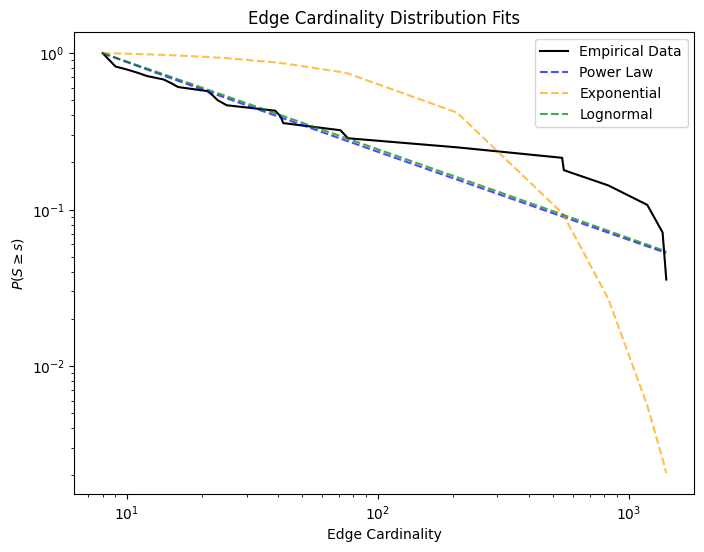

In [43]:
# Create the figure
plt.figure(figsize=(8, 6))

# Plot the empirical data (CCDF)
fit_card.plot_ccdf(color='black', label='Empirical Data')

# Plot the fitted distributions
fit_card.power_law.plot_ccdf(color='blue', linestyle='--', label='Power Law', alpha=0.7)
fit_card.exponential.plot_ccdf(color='orange', linestyle='--', label='Exponential', alpha=0.7)
fit_card.lognormal.plot_ccdf(color='green', linestyle='--', label='Lognormal', alpha=0.7)

# Formatting the plot
plt.xlabel('Edge Cardinality')
plt.ylabel('$P(S \\geq s)$')
plt.title('Edge Cardinality Distribution Fits')
plt.legend()
plt.show()

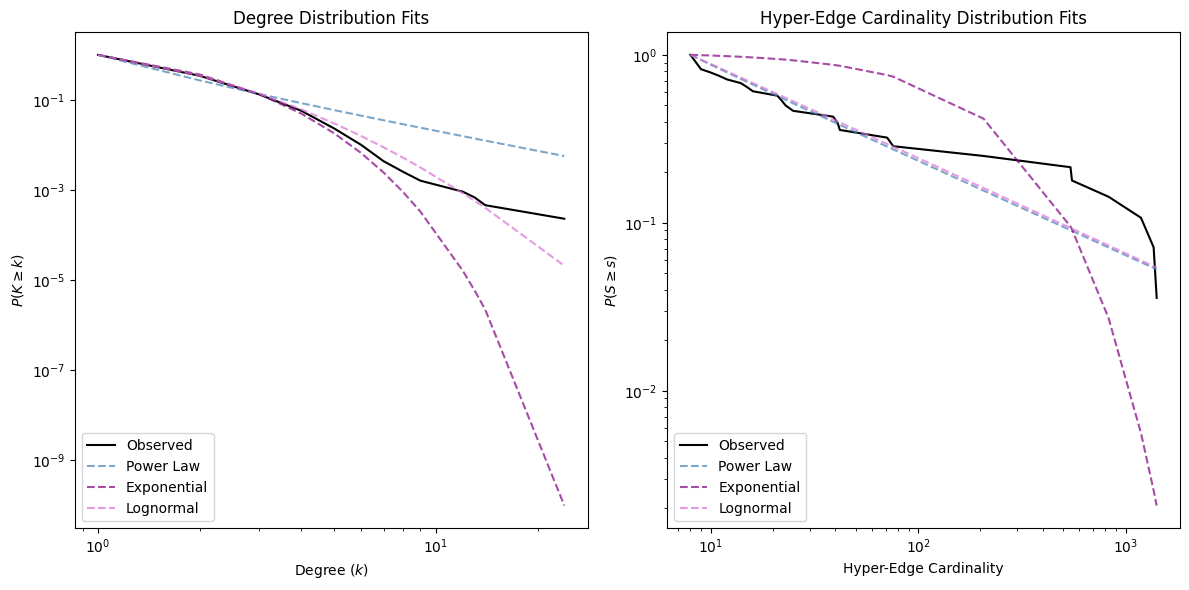

In [44]:
# Create a figure with 1 row and 2 columns
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# Plot the Degree Distribution (CCDF) on the first subplot
fit_deg.plot_ccdf(color='black', label='Observed', ax=ax1)
fit_deg.power_law.plot_ccdf(color='steelblue', linestyle='--', label='Power Law', alpha=0.7, ax=ax1)
fit_deg.exponential.plot_ccdf(color='purple', linestyle='--', label='Exponential', alpha=0.7, ax=ax1)
fit_deg.lognormal.plot_ccdf(color='orchid', linestyle='--', label='Lognormal', alpha=0.7, ax=ax1)

ax1.set_xlabel('Degree ($k$)')
ax1.set_ylabel('$P(K \\geq k)$')
ax1.set_title('Degree Distribution Fits')
ax1.legend(loc='lower left')

# Plot the Edge Cardinality Distribution (CCDF) on the second subplot
fit_card.plot_ccdf(color='black', label='Observed', ax=ax2)
fit_card.power_law.plot_ccdf(color='steelblue', linestyle='--', label='Power Law', alpha=0.7, ax=ax2)
fit_card.exponential.plot_ccdf(color='purple', linestyle='--', label='Exponential', alpha=0.7, ax=ax2)
fit_card.lognormal.plot_ccdf(color='orchid', linestyle='--', label='Lognormal', alpha=0.7, ax=ax2)

ax2.set_xlabel('Hyper-Edge Cardinality')
ax2.set_ylabel('$P(S \\geq s)$')
ax2.set_title('Hyper-Edge Cardinality Distribution Fits')
ax2.legend(loc='lower left')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

In [45]:
components = list(xgi.connected_components(H))
print(f"Connected components have sizes: {[len(component) for component in components]}")
largest = max(components, key=len)

H_lcc = xgi.subhypergraph(H, nodes=largest)
G = xgi.to_graph(H_lcc)

eigen_centralities = nx.eigenvector_centrality(G)

Connected components have sizes: [4349, 3]


## Nestedness

In [47]:
inc_mat = xgi.incidence_matrix(H)
nodf_r, nodf_c, nodf_total = nodf_rows_cols(inc_mat)

print(f"NODF rows: {100*nodf_r:.2f}%")
print(f"NODF cols: {100*nodf_c:.2f}%")
print(f"NODF total: {100*nodf_total:.2f}%")

NODF rows: 18.96%
NODF cols: 4.87%
NODF total: 18.95%


In [48]:
n_rows, n_cols = inc_mat.shape
print(n_rows, n_cols)
print(f"Possible number of protein pairs: {int((n_rows*(n_rows-1))/2)}")
print(f"Possible number of condensate pairs: {int((n_cols*(n_cols-1))/2)}")

4352 103
Possible number of protein pairs: 9467776
Possible number of condensate pairs: 5253


In [49]:
(
    df[df['uid'].isin(['500EDC60', '80EB2636'])]
    .groupby('uid')['uniprot_id']
    .apply(list)
    .reset_index()
)

,uid,uniprot_id
0,500EDC60,"[P35637, P52292, Q14974]"
1,80EB2636,"[P52292, P35637, Q14974]"


In [50]:
df[df['uid'].isin(['500EDC60', '80EB2636'])]

,uniprotkb_ac,condensate_id,condensate_name,uid,confidence_score,condensate_type,protein_count,uniprot_id,uniprotkb_id,protein_name,species_taxon_id,species_name,iupred_score,synthetic_condensate_count,role
698,P52292,80EB2636,Synthetic Condensate 000255,80EB2636,3.0,synthetic,3.0,P52292,IMA1_HUMAN,Importin subunit alpha-1,9606.0,Homo sapiens,"[0.93079, 0.915074, 0.912647, 0.852992, 0.8765...",3.0,unknown
699,P35637,80EB2636,Synthetic Condensate 000255,80EB2636,3.0,synthetic,3.0,P35637,FUS_HUMAN,RNA-binding protein FUS,9606.0,Homo sapiens,"[0.666105, 0.703578, 0.707965, 0.618285, 0.642...",42.0,unknown
708,Q14974,80EB2636,Synthetic Condensate 000255,80EB2636,3.0,synthetic,3.0,Q14974,IMB1_HUMAN,Importin subunit beta-1,9606.0,Homo sapiens,"[0.073402, 0.10481, 0.185198, 0.243554, 0.2783...",2.0,unknown
6365,P35637,500EDC60,Synthetic Condensate 000260,500EDC60,0.0,synthetic,3.0,P35637,FUS_HUMAN,RNA-binding protein FUS,9606.0,Homo sapiens,"[0.666105, 0.703578, 0.707965, 0.618285, 0.642...",42.0,unknown
6373,P52292,500EDC60,Synthetic Condensate 000260,500EDC60,0.0,synthetic,3.0,P52292,IMA1_HUMAN,Importin subunit alpha-1,9606.0,Homo sapiens,"[0.93079, 0.915074, 0.912647, 0.852992, 0.8765...",3.0,unknown
6789,Q14974,500EDC60,Synthetic Condensate 000260,500EDC60,0.0,synthetic,3.0,Q14974,IMB1_HUMAN,Importin subunit beta-1,9606.0,Homo sapiens,"[0.073402, 0.10481, 0.185198, 0.243554, 0.2783...",2.0,unknown


## Null-model comparisons and size-controlled overlaps

This section adds three controls to make the descriptive hypergraph results easier to interpret.

1. **Distribution nulls.** Node hyperdegree is compared against an edge-size-preserving null model, where each condensate keeps its observed cardinality but proteins are sampled uniformly. Edge cardinality is compared against a node-degree-preserving null model, where each protein keeps its observed hyperdegree but condensate assignments are randomized. A fill-only null is also included as a less constrained baseline.
2. **Nestedness null.** NODF is compared against fixed-row/fixed-column incidence matrices generated by bipartite double-edge swaps. This preserves both protein hyperdegrees and condensate cardinalities, so it asks whether nestedness is higher than expected after controlling for the two marginal sequences.

In [ ]:
RANDOM_SEED = 42
N_NULL_DISTRIBUTIONS = 5000
N_NULL_NODF = 1000
SWAPS_PER_INCIDENCE = 50

Incidence matrix: 4352 proteins x 103 condensates, 6877 memberships
First protein IDs: ['Q14678' 'Q86W92' 'Q9Y490' 'P10636' 'P10636-8']
First condensate IDs: ['009021FA' '03D56D03' '03E7CE7B' '08386919' '1070A586']
Incidence matrix: 4352 proteins x 103 condensates, 6877 memberships
Observed node hyperdegree range: 1-24
Observed edge cardinality range: 3-1413


,target,null_model,metric,observed,null_mean,null_q025,null_q975,empirical_p_two_sided
0,node_hyperdegree,edge-size preserving,mean,1.580193,1.580193,1.580193,1.580193,1.000000
1,node_hyperdegree,edge-size preserving,std,1.100010,1.109380,1.087827,1.131518,0.395921
2,node_hyperdegree,edge-size preserving,max,24.000000,6.367000,6.000000,8.000000,0.000400
3,node_hyperdegree,edge-size preserving,gini,0.279304,0.381557,0.373910,0.389413,0.000400
4,node_hyperdegree,fill only,mean,1.580193,1.580193,1.580193,1.580193,1.000000
5,node_hyperdegree,fill only,std,1.100010,1.246804,1.221364,1.274035,0.000400
6,node_hyperdegree,fill only,max,24.000000,7.713800,7.000000,9.000000,0.000400
7,node_hyperdegree,fill only,gini,0.279304,0.426452,0.418204,0.435068,0.000400
8,edge_cardinality,node-degree preserving,mean,66.766990,66.766990,66.766990,66.766990,1.000000
9,edge_cardinality,node-degree preserving,std,244.602797,8.056589,6.973116,9.190755,0.000400


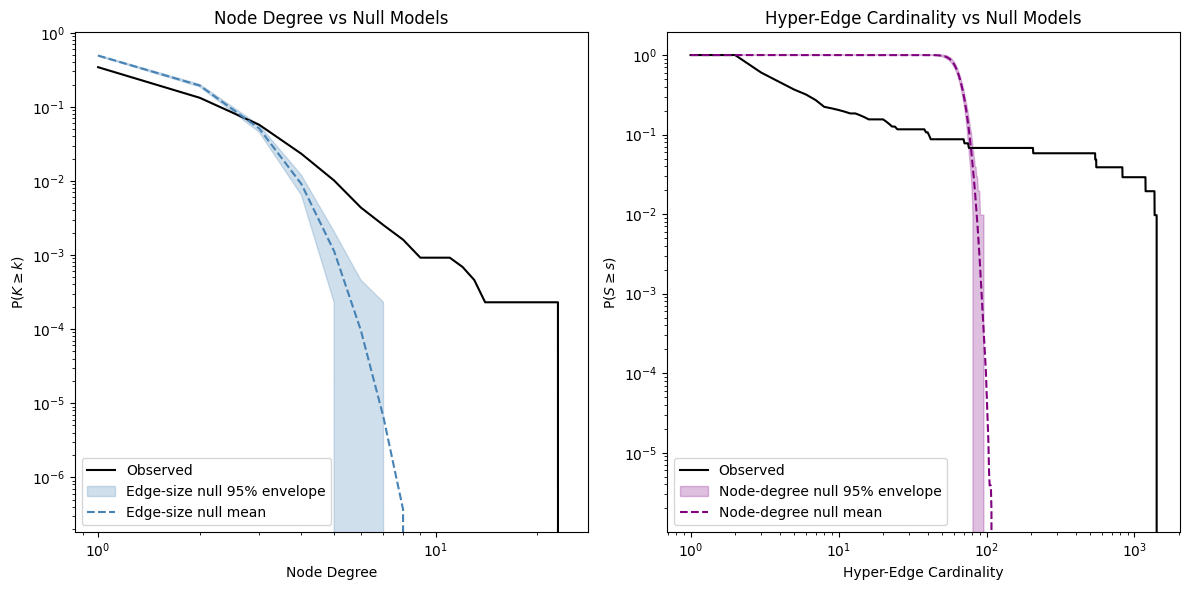

In [52]:
inc_null, node_ids_null, edge_ids_null = get_incidence_objects(H)

print(
    f"Incidence matrix: {inc_null.shape[0]} proteins x "
    f"{inc_null.shape[1]} condensates, {inc_null.nnz} memberships"
)
print("First protein IDs:", node_ids_null[:5])
print("First condensate IDs:", edge_ids_null[:5])

print(f"Incidence matrix: {inc_null.shape[0]} proteins x {inc_null.shape[1]} condensates, {inc_null.nnz} memberships")
print(f"Observed node hyperdegree range: {np.asarray(inc_null.sum(axis=1)).ravel().min()}-{np.asarray(inc_null.sum(axis=1)).ravel().max()}")
print(f"Observed edge cardinality range: {np.asarray(inc_null.sum(axis=0)).ravel().min()}-{np.asarray(inc_null.sum(axis=0)).ravel().max()}")

# Distribution null models.
dist_null_results = distribution_null_ensemble(
    inc_null,
    n_null=N_NULL_DISTRIBUTIONS,
    random_state=RANDOM_SEED,
)
plot_distribution_nulls(dist_null_results, plot_fill_null=False, figsize=(12, 6))
dist_null_summary = summarize_distribution_nulls(dist_null_results)
dist_null_summary


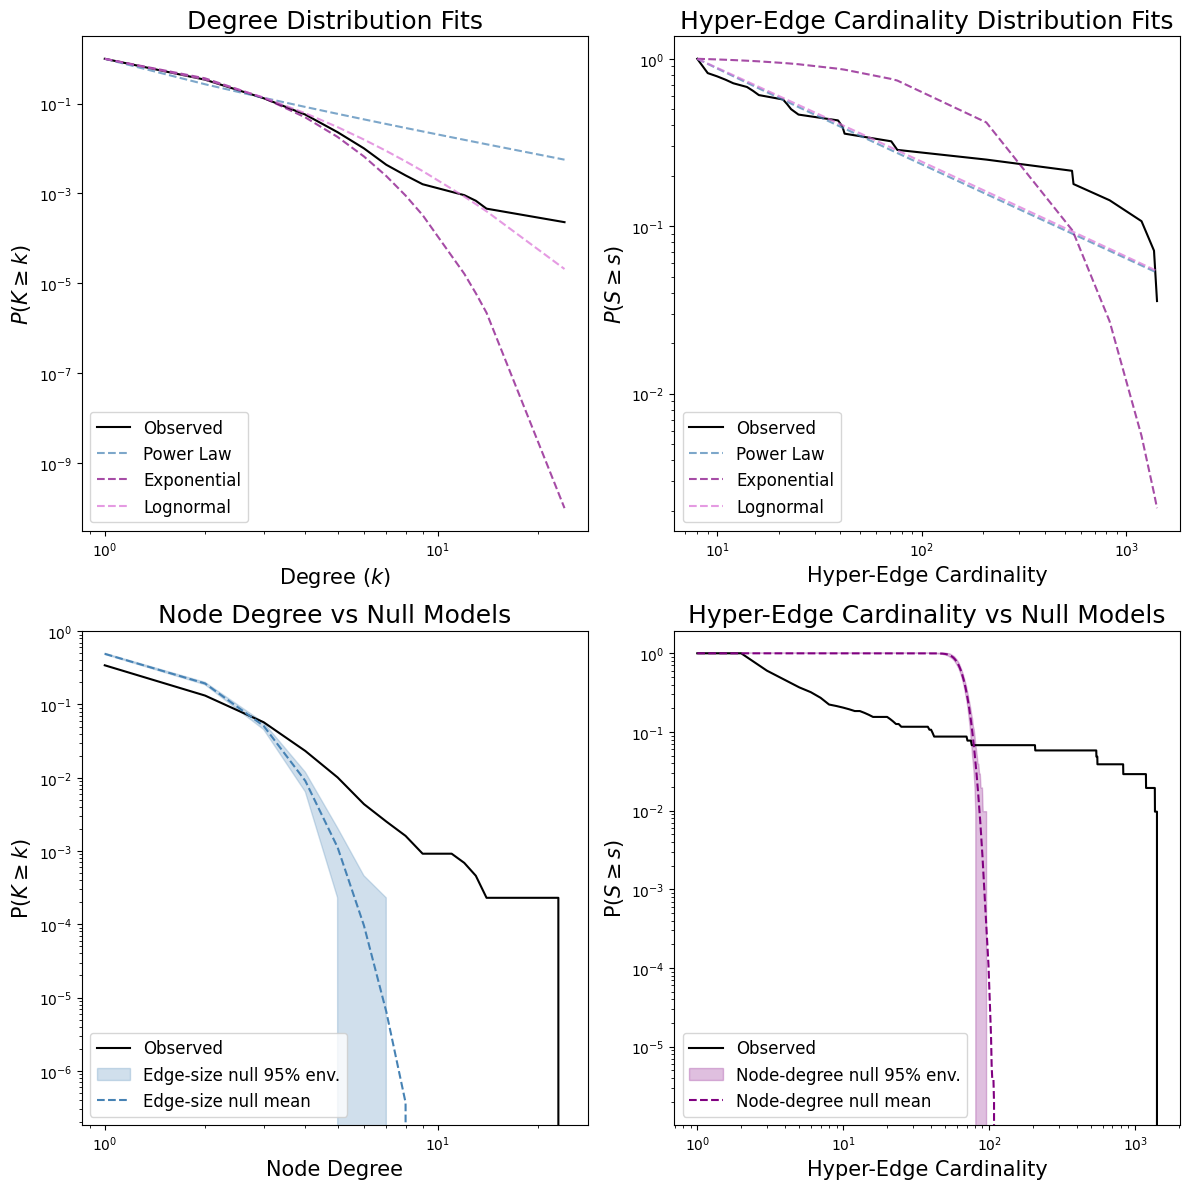

In [ ]:
# Settings for the null models
plot_fill_null = False
colors = ['steelblue', 'purple']

# Create a figure with 2 rows and 2 columns
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
(ax1, ax2), (ax3, ax4) = axes

# ---------------------------------------------------------
# Top Row: Distribution Fits (ax1, ax2)
# ---------------------------------------------------------

# Plot the Degree Distribution (CCDF) on ax1
fit_deg.plot_ccdf(color='black', label='Observed', ax=ax1)
fit_deg.power_law.plot_ccdf(color='steelblue', linestyle='--', label='Power Law', alpha=0.7, ax=ax1)
fit_deg.exponential.plot_ccdf(color='purple', linestyle='--', label='Exponential', alpha=0.7, ax=ax1)
fit_deg.lognormal.plot_ccdf(color='orchid', linestyle='--', label='Lognormal', alpha=0.7, ax=ax1)

ax1.set_xlabel('Degree ($k$)', fontsize=15)
ax1.set_ylabel('$P(K \\geq k)$', fontsize=15)
ax1.set_title('Degree Distribution Fits', fontsize=18)
ax1.legend(loc='lower left', fontsize=12)

# Plot the Edge Cardinality Distribution (CCDF) on ax2
fit_card.plot_ccdf(color='black', label='Observed', ax=ax2)
fit_card.power_law.plot_ccdf(color='steelblue', linestyle='--', label='Power Law', alpha=0.7, ax=ax2)
fit_card.exponential.plot_ccdf(color='purple', linestyle='--', label='Exponential', alpha=0.7, ax=ax2)
fit_card.lognormal.plot_ccdf(color='orchid', linestyle='--', label='Lognormal', alpha=0.7, ax=ax2)

ax2.set_xlabel('Hyper-Edge Cardinality', fontsize=15)
ax2.set_ylabel('$P(S \\geq s)$', fontsize=15)
ax2.set_title('Hyper-Edge Cardinality Distribution Fits', fontsize=18)
ax2.legend(loc='lower left', fontsize=12)


# ---------------------------------------------------------
# Bottom Row: Distribution Nulls (ax3, ax4)
# ---------------------------------------------------------

# Extract data for null models
obs_deg = dist_null_results["observed_node_degree"]
obs_size = dist_null_results["observed_edge_size"]

deg_support = np.arange(1, max(obs_deg.max(), max(x.max() for x in dist_null_results["node_degree_edge_size_null"])) + 1)
size_support = np.arange(1, max(obs_size.max(), max(x.max() for x in dist_null_results["edge_size_node_degree_null"])) + 1)

deg_null = np.vstack([ccdf(x, deg_support) for x in dist_null_results["node_degree_edge_size_null"]])
deg_fill = np.vstack([ccdf(x, deg_support) for x in dist_null_results["node_degree_fill_null"]])
size_null = np.vstack([ccdf(x, size_support) for x in dist_null_results["edge_size_node_degree_null"]])
size_fill = np.vstack([ccdf(x, size_support) for x in dist_null_results["edge_size_fill_null"]])

# Plot Node Degree Null Models on ax3
ax3.plot(deg_support, ccdf(obs_deg, deg_support), color="black", label="Observed")
ax3.fill_between(deg_support, *np.quantile(deg_null, [0.025, 0.975], axis=0), color=colors[0], alpha=0.25, label="Edge-size null 95% env.")
ax3.plot(deg_support, deg_null.mean(axis=0), color=colors[0], ls="--", label="Edge-size null mean")
if plot_fill_null:
    ax3.fill_between(deg_support, *np.quantile(deg_fill, [0.025, 0.975], axis=0), color="tab:gray", alpha=0.18, label="Fill-only null 95% env.")
ax3.set_xscale("log")
ax3.set_yscale("log")
ax3.set_xlabel("Node Degree", fontsize=15)
ax3.set_ylabel("P($K \\geq k$)", fontsize=15)
ax3.set_title("Node Degree vs Null Models", fontsize=18)
ax3.legend(loc='lower left', fontsize=12)

# Plot Hyper-Edge Cardinality Null Models on ax4
ax4.plot(size_support, ccdf(obs_size, size_support), color="black", label="Observed")
ax4.fill_between(size_support, *np.quantile(size_null, [0.025, 0.975], axis=0), color=colors[1], alpha=0.25, label="Node-degree null 95% env.")
ax4.plot(size_support, size_null.mean(axis=0), color=colors[1], ls="--", label="Node-degree null mean")
if plot_fill_null:
    ax4.fill_between(size_support, *np.quantile(size_fill, [0.025, 0.975], axis=0), color="tab:gray", alpha=0.18, label="Fill-only null 95% env.")
ax4.set_xscale("log")
ax4.set_yscale("log")
ax4.set_xlabel("Hyper-Edge Cardinality", fontsize=15)
ax4.set_ylabel("P($S \\geq s$)", fontsize=15)
ax4.set_title("Hyper-Edge Cardinality vs Null Models", fontsize=18)
ax4.legend(loc='lower left', fontsize=12)

# Adjust layout to prevent overlap and display
plt.tight_layout()
plt.show()

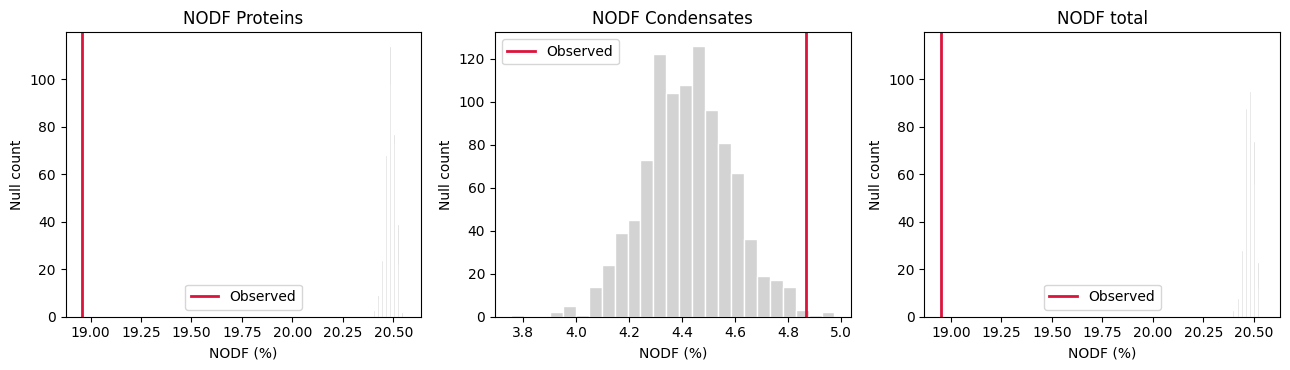

,component,observed,null_mean,null_sd,null_q025,null_q975,z_score,empirical_p_two_sided,observed_percent,null_mean_percent,null_q025_percent,null_q975_percent
0,rows,0.189567,0.204850,0.000251,0.204312,0.205292,-60.874148,0.001998,18.956656,20.485004,20.431169,20.529153
1,columns,0.048673,0.044205,0.001647,0.041033,0.047469,2.713169,0.007992,4.867278,4.420541,4.103270,4.746863
2,total,0.189488,0.204761,0.000251,0.204223,0.205202,-60.886377,0.001998,18.948843,20.476096,20.422279,20.520226


In [54]:
# NODF compared with a fixed-row/fixed-column swap null.
# This preserves both protein hyperdegrees and condensate cardinalities.
nodf_null_summary, nodf_observed_values, nodf_null_values = nodf_fixed_fixed_null(
    inc_null,
    n_null=N_NULL_NODF,
    swaps_per_incidence=SWAPS_PER_INCIDENCE,
    random_state=RANDOM_SEED
    )
plot_nodf_null(nodf_null_summary, nodf_null_values)
nodf_null_summary.assign(
    observed_percent=lambda d: 100 * d["observed"],
    null_mean_percent=lambda d: 100 * d["null_mean"],
    null_q025_percent=lambda d: 100 * d["null_q025"],
    null_q975_percent=lambda d: 100 * d["null_q975"],
)


## Robustness check: removing the largest condensate

The null-model results above are dominated by one very large condensate (edge cardinality up to ~1,400 proteins, while the median is far smaller). This section repeats the same analyses after removing that single hyperedge, to see which conclusions depend on it.

The simulation counts (`N_NULL_DISTRIBUTIONS`, `N_NULL_NODF`, `SWAPS_PER_INCIDENCE`) are reused from the null-model section, so changing them there changes both analyses.

In [55]:
# --- Identify and remove the largest condensate ---------------------------------
edge_size_map = H.edges.size.asdict()
largest_edge_id = max(edge_size_map, key=edge_size_map.get)

largest_info = df[df['condensate_id'] == largest_edge_id].iloc[0]
print(f"Largest condensate: {largest_edge_id}")
print(f"  name: {largest_info['condensate_name']}")
print(f"  type: {largest_info['condensate_type']}")
print(f"  proteins: {edge_size_map[largest_edge_id]}")

H_nomax = H.copy()
H_nomax.remove_edge(largest_edge_id)

# Proteins that only belonged to the removed condensate are now isolated -> drop them
orphans = [n for n, d in H_nomax.nodes.degree.asdict().items() if d == 0]
H_nomax.remove_nodes_from(orphans)

print(f"\nRemoved {len(orphans)} proteins that were only in this condensate")
print(f"Original:  {H.num_nodes} proteins, {H.num_edges} condensates")
print(f"Without it: {H_nomax.num_nodes} proteins, {H_nomax.num_edges} condensates")

# Matching dataframe (same filter as the hypergraph)
df_nomax = df[df['condensate_id'] != largest_edge_id]
cond_nomax = df_nomax.drop_duplicates(subset=['condensate_id'])
print("\nCondensates by type:")
print(cond_nomax['condensate_type'].value_counts())
print("\nProteins per condensate, by type:")
print(cond_nomax.groupby('condensate_type')['protein_count'].describe())

Largest condensate: 91857CE7
  name: Nucleolus
  type: biomolecular
  proteins: 1413

Removed 725 proteins that were only in this condensate
Original:  4352 proteins, 103 condensates
Without it: 3627 proteins, 102 condensates

Condensates by type:
condensate_type
biomolecular    67
synthetic       31
infectious       4
Name: count, dtype: int64

Proteins per condensate, by type:
                 count       mean         std  min   25%  50%   75%     max
condensate_type                                                            
biomolecular      67.0  79.641791  252.724590  3.0  3.00  5.0  14.5  1366.0
infectious         4.0   5.250000    1.258306  4.0  4.75  5.0   5.5     7.0
synthetic         31.0   3.935484    1.691853  3.0  3.00  3.0   4.0    10.0


In [56]:
# --- Descriptive statistics and connectivity ------------------------------------
describe_hypergraph(H_nomax)
print(f"\nHypergraph assortativity coefficient: {xgi.degree_assortativity(H_nomax)}")

components_nomax = list(xgi.connected_components(H_nomax))
print(f"Connected components have sizes: {[len(c) for c in components_nomax]}")

largest_cc_nomax = max(components_nomax, key=len)
H_lcc_nomax = xgi.subhypergraph(H_nomax, nodes=largest_cc_nomax)
G_nomax = xgi.to_graph(H_lcc_nomax)
eigen_centralities_nomax = nx.eigenvector_centrality(G_nomax, max_iter=1000)

Number of proteins (nodes): 3627
Number of biomolecular condensates (hyperedges): 102

Hypergraph incidence density: 1.48%
Global clustering coefficient: 91.26%
The hypergraph is NOT connected.

Hypergraph assortativity coefficient: 0.27210405381963465
Connected components have sizes: [3624, 3]


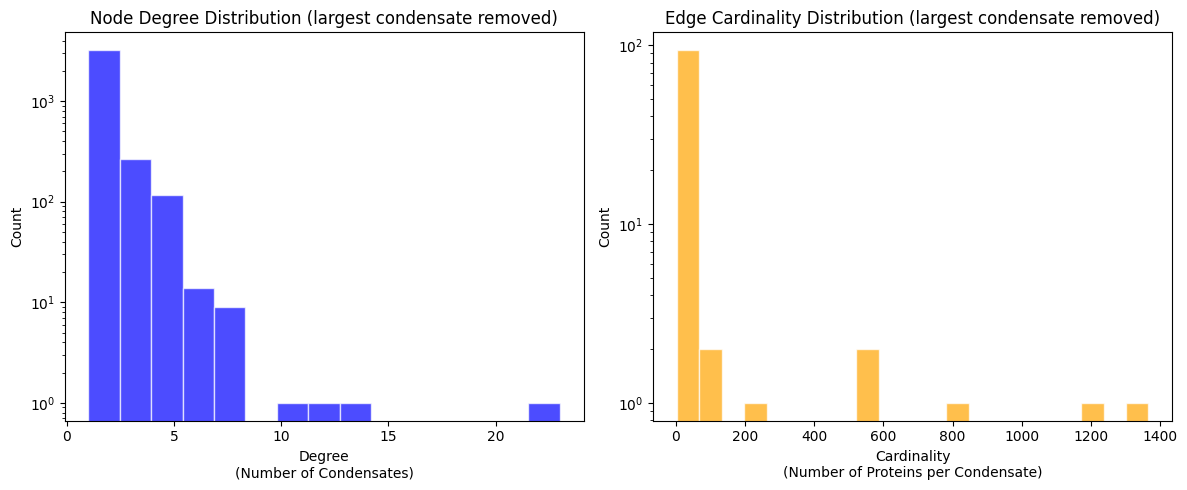

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 10/10 [00:00<00:00, 507.88it/s]
c:\Users\gabri\anaconda3\envs\hypergraphs\Lib\site-packages\powerlaw\distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,



(Degree Distribution) Power Law Exponent (gamma): 2.51
(Degree Distribution) Minimum value for fit (xmin): 1.0
(Degree Distribution) Fraction of observations above xmin: 31.98%
(Degree Distribution) power_law vs exponential: loglikelihood ratio = -5.817, p-value = 6.004e-09
(Degree Distribution) power_law vs lognormal: loglikelihood ratio = -10.260, p-value = 1.064e-24
(Degree Distribution) lognormal vs exponential: loglikelihood ratio = 1.500, p-value = 0.1337
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 26/26 [00:00<00:00, 1323.19it/s]


(Edge Cardinalities) Power Law Exponent (gamma): 1.61
(Edge Cardinalities) Minimum value for fit (xmin): 8.0
(Edge Cardinalities) Fraction of observations above xmin: 21.57%
(Edge Cardinalities) power_law vs exponential: loglikelihood ratio = 4.159, p-value = 3.193e-05
(Edge Cardinalities) power_law vs lognormal: loglikelihood ratio = -2.157, p-value = 0.03099
(Edge Cardinalities) lognormal vs exponential: loglikelihood ratio = 4.160, p-value = 3.187e-05



c:\Users\gabri\anaconda3\envs\hypergraphs\Lib\site-packages\powerlaw\distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution exponential; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')
c:\Users\gabri\anaconda3\envs\hypergraphs\Lib\site-packages\powerlaw\distributions.py:776: UserWarning: No valid fits found for distribution lognormal.
  warnings.warn(f"No valid fits found for distribution {self.name}.")


In [57]:
# --- Degree and edge-cardinality distributions ----------------------------------
edge_sizes_nomax = H_nomax.edges.size.asnumpy()
degrees_nomax = H_nomax.nodes.degree.asnumpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(degrees_nomax, bins=15, color='blue', edgecolor='white', alpha=0.7)
ax1.set_title("Node Degree Distribution (largest condensate removed)")
ax1.set_xlabel("Degree\n(Number of Condensates)")
ax1.set_ylabel("Count")
ax1.set_yscale("log")

ax2.hist(edge_sizes_nomax, bins='auto', color='orange', edgecolor='white', alpha=0.7)
ax2.set_title("Edge Cardinality Distribution (largest condensate removed)")
ax2.set_xlabel("Cardinality\n(Number of Proteins per Condensate)")
ax2.set_ylabel("Count")
ax2.set_yscale("log")
plt.tight_layout()
plt.show()


def fit_and_report(values, label):
    """Fit a discrete power law and compare it against exponential / lognormal alternatives."""
    values = np.asarray(values)
    fit = powerlaw.Fit(values, discrete=True)
    xmin = fit.power_law.xmin
    print(f"\n({label}) Power Law Exponent (gamma): {fit.power_law.alpha:.2f}")
    print(f"({label}) Minimum value for fit (xmin): {xmin}")
    print(f"({label}) Fraction of observations above xmin: {100 * np.mean(values > xmin):.2f}%")
    for a, b in [("power_law", "exponential"), ("power_law", "lognormal"), ("lognormal", "exponential")]:
        R, p = fit.distribution_compare(a, b, normalized_ratio=True)
        print(f"({label}) {a} vs {b}: loglikelihood ratio = {R:.3f}, p-value = {p:.4g}")
    return fit


fit_deg_nomax = fit_and_report(degrees_nomax, "Degree Distribution")
fit_card_nomax = fit_and_report(edge_sizes_nomax, "Edge Cardinalities")

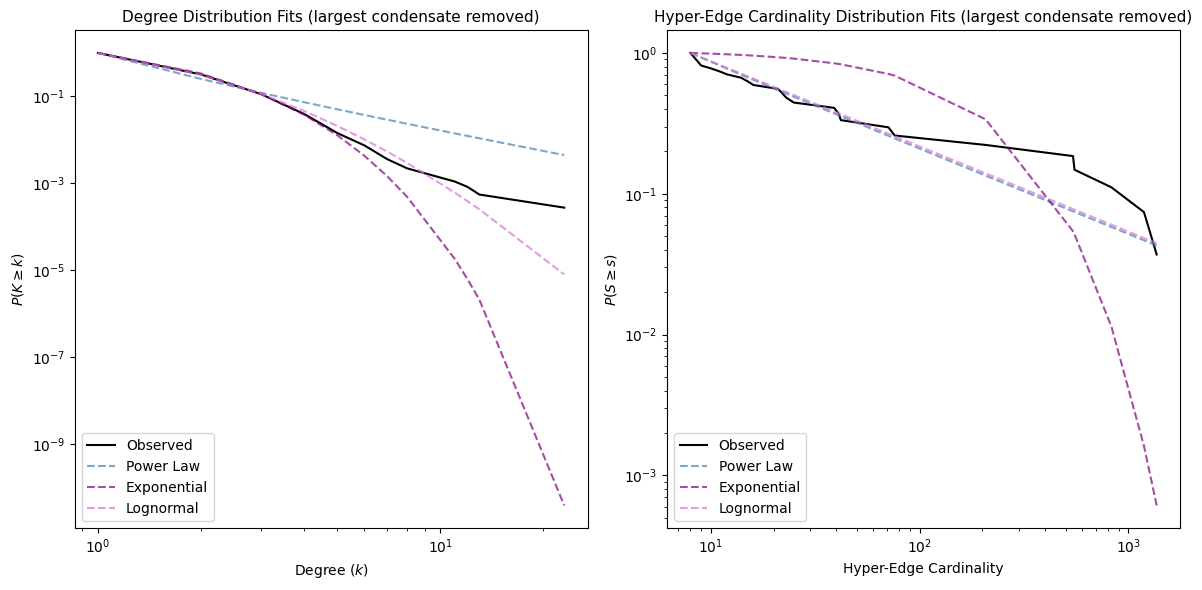

In [58]:
# --- CCDF fits ------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

for ax, fit, xlabel, ylabel, title in [
    (ax1, fit_deg_nomax, 'Degree ($k$)', '$P(K \\geq k)$', 'Degree Distribution Fits'),
    (ax2, fit_card_nomax, 'Hyper-Edge Cardinality', '$P(S \\geq s)$', 'Hyper-Edge Cardinality Distribution Fits'),
]:
    fit.plot_ccdf(color='black', label='Observed', ax=ax)
    fit.power_law.plot_ccdf(color='steelblue', linestyle='--', label='Power Law', alpha=0.7, ax=ax)
    fit.exponential.plot_ccdf(color='purple', linestyle='--', label='Exponential', alpha=0.7, ax=ax)
    fit.lognormal.plot_ccdf(color='orchid', linestyle='--', label='Lognormal', alpha=0.7, ax=ax)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title + " (largest condensate removed)", fontsize=11)
    ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

In [59]:
# --- Nestedness (observed) ------------------------------------------------------
inc_mat_nomax = xgi.incidence_matrix(H_nomax)
nodf_r_nomax, nodf_c_nomax, nodf_total_nomax = nodf_rows_cols(inc_mat_nomax)

print(f"NODF rows: {100*nodf_r_nomax:.2f}%")
print(f"NODF cols: {100*nodf_c_nomax:.2f}%")
print(f"NODF total: {100*nodf_total_nomax:.2f}%")

n_rows_nomax, n_cols_nomax = inc_mat_nomax.shape
print(f"\nIncidence matrix: {n_rows_nomax} x {n_cols_nomax}")
print(f"Possible number of protein pairs: {int(n_rows_nomax * (n_rows_nomax - 1) / 2)}")
print(f"Possible number of condensate pairs: {int(n_cols_nomax * (n_cols_nomax - 1) / 2)}")

NODF rows: 17.78%
NODF cols: 4.36%
NODF total: 17.76%

Incidence matrix: 3627 x 102
Possible number of protein pairs: 6575751
Possible number of condensate pairs: 5151


Incidence matrix: 3627 proteins x 102 condensates, 5464 memberships
Observed node hyperdegree range: 1-23
Observed edge cardinality range: 3-1366


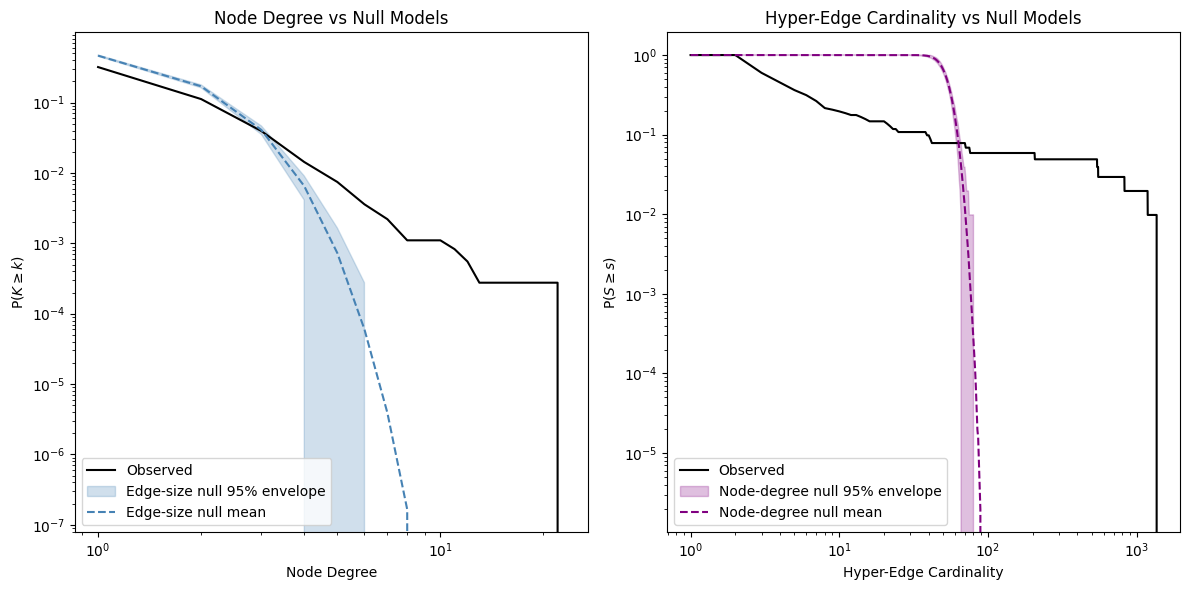

,target,null_model,metric,observed,null_mean,null_q025,null_q975,empirical_p_two_sided
0,node_hyperdegree,edge-size preserving,mean,1.506479,1.506479,1.506479,1.506479,1.0000
1,node_hyperdegree,edge-size preserving,std,1.006266,1.074691,1.051552,1.097984,0.0004
2,node_hyperdegree,edge-size preserving,max,23.000000,6.151800,5.000000,7.000000,0.0004
3,node_hyperdegree,edge-size preserving,gini,0.258724,0.386714,0.378078,0.395335,0.0004
4,node_hyperdegree,fill only,mean,1.506479,1.506479,1.506479,1.506479,1.0000
5,node_hyperdegree,fill only,std,1.006266,1.217862,1.189577,1.246622,0.0004
6,node_hyperdegree,fill only,max,23.000000,7.458200,6.000000,9.000000,0.0004
7,node_hyperdegree,fill only,gini,0.258724,0.435897,0.426372,0.445337,0.0004
8,edge_cardinality,node-degree preserving,mean,53.568627,53.568627,53.568627,53.568627,1.0000
9,edge_cardinality,node-degree preserving,std,206.094235,7.218129,6.248898,8.236141,0.0004


In [60]:
# --- Distribution null models ---------------------------------------------------
inc_nomax, node_ids_nomax, edge_ids_nomax = get_incidence_objects(H_nomax)

print(f"Incidence matrix: {inc_nomax.shape[0]} proteins x {inc_nomax.shape[1]} condensates, {inc_nomax.nnz} memberships")
print(f"Observed node hyperdegree range: {np.asarray(inc_nomax.sum(axis=1)).ravel().min()}-{np.asarray(inc_nomax.sum(axis=1)).ravel().max()}")
print(f"Observed edge cardinality range: {np.asarray(inc_nomax.sum(axis=0)).ravel().min()}-{np.asarray(inc_nomax.sum(axis=0)).ravel().max()}")

dist_null_results_nomax = distribution_null_ensemble(
    inc_nomax,
    n_null=N_NULL_DISTRIBUTIONS,
    random_state=RANDOM_SEED,
)
plot_distribution_nulls(dist_null_results_nomax, plot_fill_null=False, figsize=(12, 6))
plt.show()

dist_null_summary_nomax = summarize_distribution_nulls(dist_null_results_nomax)
dist_null_summary_nomax

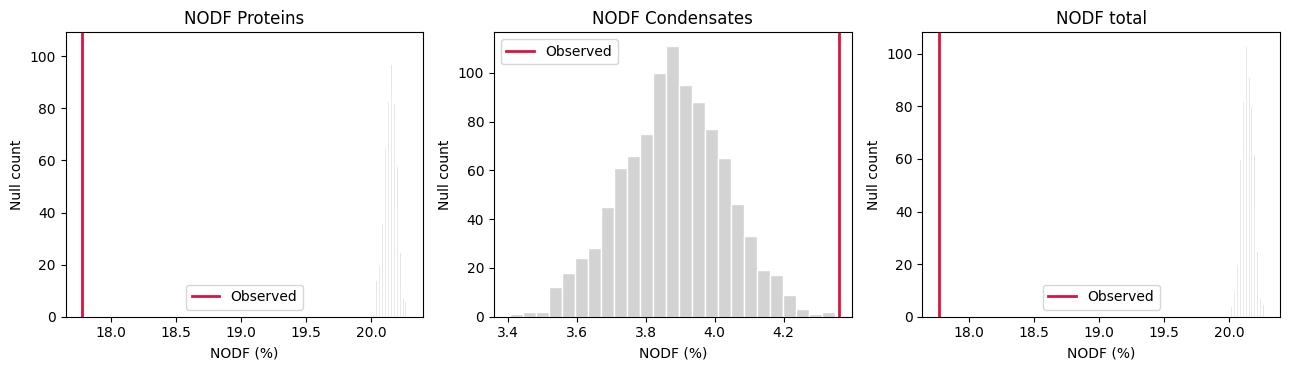

,component,observed,null_mean,null_sd,null_q025,null_q975,z_score,empirical_p_two_sided,observed_percent,null_mean_percent,null_q025_percent,null_q975_percent
0,rows,0.177750,0.201485,0.000474,0.200472,0.202377,-50.076230,0.001998,17.775042,20.148460,20.047176,20.237712
1,columns,0.043616,0.038799,0.001506,0.035758,0.041749,3.198863,0.001998,4.361616,3.879944,3.575828,4.174898
2,total,0.177645,0.201357,0.000473,0.200346,0.202248,-50.091007,0.001998,17.764543,20.135726,20.034587,20.224755


In [61]:
# --- NODF vs fixed-row / fixed-column swap null ---------------------------------
nodf_null_summary_nomax, nodf_observed_values_nomax, nodf_null_values_nomax = nodf_fixed_fixed_null(
    inc_nomax,
    n_null=N_NULL_NODF,
    swaps_per_incidence=SWAPS_PER_INCIDENCE,
    random_state=RANDOM_SEED,
)
plot_nodf_null(nodf_null_summary_nomax, nodf_null_values_nomax)
nodf_null_summary_nomax.assign(
    observed_percent=lambda d: 100 * d["observed"],
    null_mean_percent=lambda d: 100 * d["null_mean"],
    null_q025_percent=lambda d: 100 * d["null_q025"],
    null_q975_percent=lambda d: 100 * d["null_q975"],
)

In [ ]:
comparison = pd.DataFrame({
    "full hypergraph": headline_stats(H, inc_null, fit_deg, fit_card),
    "largest condensate removed": headline_stats(H_nomax, inc_nomax, fit_deg_nomax, fit_card_nomax),
})
comparison.round(3)

,full hypergraph,largest condensate removed
proteins (nodes),4352.000,3627.000
condensates (hyperedges),103.000,102.000
incidence density (%),1.534,1.477
mean clustering coefficient (%),89.428,91.263
connected components,2.000,2.000
degree gamma,2.426,2.512
degree xmin,1.000,1.000
cardinality gamma,1.562,1.605
cardinality xmin,8.000,8.000
NODF rows (%),18.957,17.775
